# Day 3 — Model Performance + Regularization
### ML Dojo · for bioinformatics & clinical systems biology

**Dataset:** a published proteomics dataset (PubMed ID 31642809, per the file name): **23 donors** (10 aged 80+, 13 aged 20–34) × **2,509 proteins**, already log-transformed and centred.

This is the regime Day 1 warned about: **p ≫ n** (≈ 100 features per sample). Ordinary regression can fit anything here, so the two questions of today are:

1. **How do we measure performance honestly** with only 23 samples? → cross-validation, done right.
2. **How do we fit a model at all** when p ≫ n? → regularisation (ridge, LASSO).

**By the end of today you will be able to:**
- Explain why a single train/test split is unreliable for small cohorts, and choose a CV scheme.
- Fit ridge and LASSO logistic regression and read their coefficient paths.
- Tune the penalty with **nested** cross-validation.
- Recognise **selection leakage**, the trap that makes noise look like a perfect biomarker.
- Judge how **stable** a LASSO "biomarker signature" really is.

## 0. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import (GridSearchCV, LeaveOneOut, RepeatedStratifiedKFold,
                                     StratifiedKFold, cross_val_predict, cross_val_score,
                                     permutation_test_score, train_test_split)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", context="notebook")
SEED = 42

DATA = Path("../data/biomarker-analyses/legacy code/31642809_Age_Old_Young.csv")
df = pd.read_csv(DATA)

X = df.drop(columns=["Sample_Name", "Age_Group"])
X.columns = X.columns.str.replace(r"^X(?=\d)", "", regex=True)   # undo R's "X" prefix for names starting with a digit
y = (df["Age_Group"] == "80+").astype(int).rename("old")          # 1 = aged 80+, 0 = aged 20-34
print(f"{X.shape[0]} samples × {X.shape[1]} proteins | old = {y.sum()}, young = {(1 - y).sum()}")
X.iloc[:5, :6]

23 samples × 2509 proteins | old = 10, young = 13


,1433B_HUMAN,1433E_HUMAN,1433F_HUMAN,1433G_HUMAN,1433T_HUMAN,1433Z_HUMAN
0,0.068576,-0.007028,-0.028479,0.006766,0.077415,0.119030
1,0.282225,0.049810,0.228958,-0.041928,0.560979,0.524830
2,-0.000807,-0.073465,0.001079,-0.056669,0.137135,0.062819
3,0.081502,-0.009757,0.034295,-0.015409,-0.081737,-0.083687
4,0.067736,0.061976,0.177834,0.129802,0.105837,0.028637


### A first look: PCA

With thousands of features, start with an unsupervised overview. If the groups separate on the first principal components, there is strong signal; if not, any classifier deserves extra suspicion.

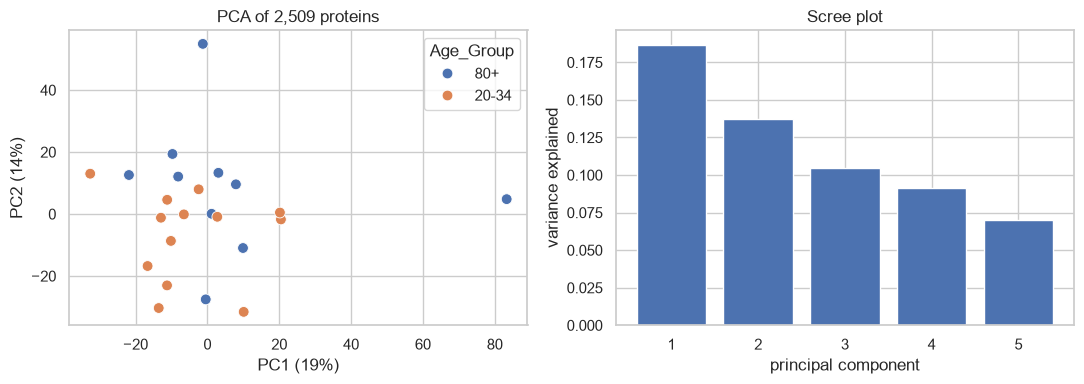

In [2]:
Z = StandardScaler().fit_transform(X)
pca = PCA(n_components=5).fit(Z)
pcs = pca.transform(Z)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=df["Age_Group"], s=60, ax=axes[0])
axes[0].set(xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.0%})",
            ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.0%})", title="PCA of 2,509 proteins")
axes[1].bar(range(1, 6), pca.explained_variance_ratio_)
axes[1].set(xlabel="principal component", ylabel="variance explained", title="Scree plot")
plt.tight_layout()

Age group is visible in the leading components, so there is genuine signal. (PCA here is purely exploratory: it never saw the labels. Using it as a preprocessing step for a classifier would need to happen *inside* cross-validation, as we'll see.)

## 1. Why one train/test split is not enough

On Days 1–2 we held out 30%. Here that means a test set of **7 donors**. Let's repeat the split 200 times and see how much the test AUC of the *same* model moves, in two settings:
- **all 2,509 proteins:** a very strong signal (old vs young is a big biological contrast),
- **50 random proteins:** a weaker signal, closer to a typical targeted biomarker panel.

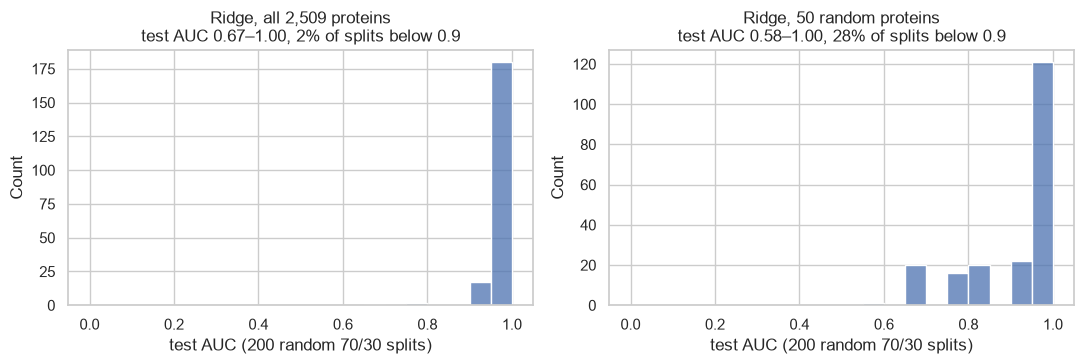

In [3]:
def make_model(C=1.0, l1_ratio=0):
    # l1_ratio=0 -> ridge (L2) penalty, l1_ratio=1 -> LASSO (L1). C = 1/lambda: smaller C = stronger penalty.
    return make_pipeline(StandardScaler(),
                         LogisticRegression(C=C, l1_ratio=l1_ratio, solver="liblinear", max_iter=5000))

def split_aucs(features, n=200):
    aucs = []
    for i in range(n):
        X_tr, X_te, y_tr, y_te = train_test_split(X[features], y, test_size=0.3, stratify=y, random_state=i)
        aucs.append(roc_auc_score(y_te, make_model().fit(X_tr, y_tr).predict_proba(X_te)[:, 1]))
    return np.array(aucs)

panel50 = X.columns[np.random.default_rng(SEED).choice(X.shape[1], 50, replace=False)]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
for ax, (label, feats) in zip(axes, [("all 2,509 proteins", X.columns), ("50 random proteins", panel50)]):
    a = split_aucs(feats)
    sns.histplot(a, bins=np.linspace(0, 1, 21), ax=ax)
    ax.set(title=f"Ridge, {label}\ntest AUC {a.min():.2f}–{a.max():.2f}, {np.mean(a < 0.9):.0%} of splits below 0.9",
           xlabel="test AUC (200 random 70/30 splits)")
plt.tight_layout()

With the full proteome almost every split scores near 1, but even here a few unlucky splits drop well below. With a weaker signal, the **same model** looks mediocre or excellent depending on which 7 donors land in the test set. A single split wastes data (30% never used for training) **and** gives a noisy estimate. Cross-validation fixes both.

## 2. Cross-validation

**k-fold CV:** split the data into *k* folds; train on *k − 1*, test on the held-out fold; rotate so every sample is tested exactly once; average.

```
fold 1:  [TEST][train][train][train][train]
fold 2:  [train][TEST][train][train][train]
 ...
fold 5:  [train][train][train][train][TEST]
```

Common choices for small biomedical cohorts:

| Scheme | Notes |
|---|---|
| **Stratified k-fold** (k = 5 or 10) | keeps the class ratio in every fold — the default for classification |
| **Repeated stratified k-fold** | repeat with different shuffles and average → much less dependence on one lucky partition |
| **Leave-one-out (LOOCV)** | k = n; nearly unbiased but high variance, and per-fold AUC is undefined (1 test sample) — pool predictions instead |
| **Grouped k-fold** | keeps all samples of a patient / batch / site together — essential with repeated measures |

In [4]:
model = make_model()
results = {}

s5 = cross_val_score(model, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring="roc_auc")
results["5-fold (one shuffle)"] = (s5.mean(), s5.std())

rep = RepeatedStratifiedKFold(n_splits=5, n_repeats=20, random_state=SEED)
s_rep = cross_val_score(model, X, y, cv=rep, scoring="roc_auc")
results["5-fold × 20 repeats"] = (s_rep.mean(), s_rep.std())

p_loo = cross_val_predict(model, X, y, cv=LeaveOneOut(), method="predict_proba")[:, 1]
results["LOOCV (pooled predictions)"] = (roc_auc_score(y, p_loo), np.nan)

pd.DataFrame(results, index=["mean AUC", "SD across folds"]).T.round(3)

,mean AUC,SD across folds
5-fold (one shuffle),1.0,0.0
5-fold × 20 repeats,1.0,0.0
LOOCV (pooled predictions),1.0,NaN


Prediction of age group from the full proteome is essentially perfect in this dataset (AUC ≈ 1). That is common for strong biological contrasts like 20 vs 80+ years. The interesting questions are therefore **which proteins** the model uses and **how much we can trust that list**.

## 3. Regularisation

With 2,509 proteins and 23 samples, unpenalised logistic regression has infinitely many perfect solutions (Day 2's separation problem, ×1000). Regularisation adds a cost for large coefficients:

$$\text{minimise}\quad \underbrace{\text{log-loss}(\beta)}_{\text{fit the data}} \;+\; \lambda \cdot \underbrace{\text{penalty}(\beta)}_{\text{keep it simple}}$$

| | Penalty | Effect | Good for |
|---|---|---|---|
| **Ridge (L2)** | $\sum \beta_j^2$ | shrinks all coefficients towards 0, keeps every protein | prediction with many small, correlated effects |
| **LASSO (L1)** | $\sum \lvert\beta_j\rvert$ | sets most coefficients **exactly to 0** → feature selection | short biomarker panels |
| **Elastic net** | mix of both | selects groups of correlated proteins together | omics with co-regulated modules |

In scikit-learn the strength is set by **C = 1/λ**: *small C = strong penalty = simpler model*.

### Performance across penalty strengths

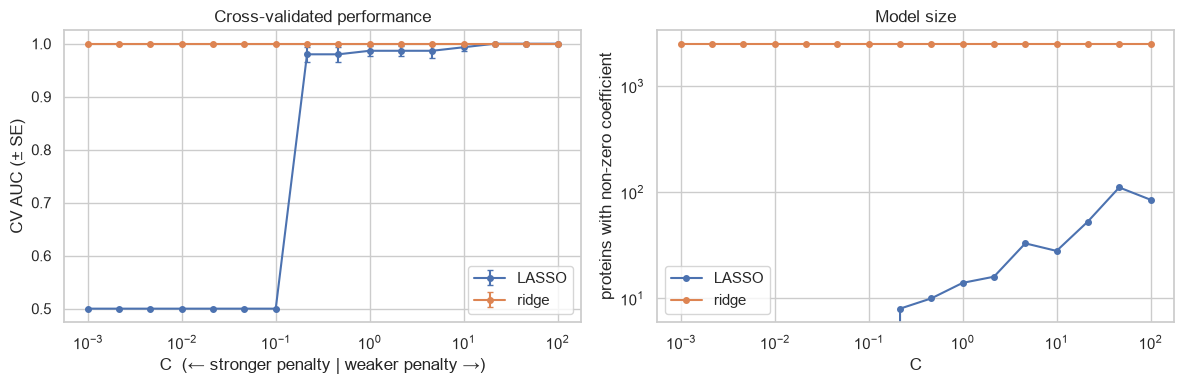

In [5]:
Cs = np.logspace(-3, 2, 16)
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)
curve = []
for C in Cs:
    for name, l1 in [("ridge", 0), ("LASSO", 1)]:
        s = cross_val_score(make_model(C, l1), X, y, cv=cv, scoring="roc_auc")
        n_nonzero = (make_model(C, l1).fit(X, y)[-1].coef_ != 0).sum()
        curve.append({"C": C, "model": name, "AUC": s.mean(), "SE": s.std() / np.sqrt(len(s)), "nonzero": n_nonzero})
curve = pd.DataFrame(curve)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, g in curve.groupby("model"):
    axes[0].errorbar(g["C"], g["AUC"], yerr=g["SE"], marker="o", ms=4, capsize=2, label=name)
    axes[1].plot(g["C"], g["nonzero"], marker="o", ms=4, label=name)
axes[0].set(xscale="log", xlabel="C  (← stronger penalty | weaker penalty →)", ylabel="CV AUC (± SE)",
            title="Cross-validated performance")
axes[1].set(xscale="log", yscale="log", xlabel="C", ylabel="proteins with non-zero coefficient",
            title="Model size")
axes[0].legend(); axes[1].legend(); plt.tight_layout()

- **Ridge** always keeps all 2,509 proteins; its performance is flat over a wide range of C.
- **LASSO** with a strong penalty (left) keeps zero proteins and predicts nothing (AUC 0.5); as C grows it lets in a handful, then dozens of proteins.
- A LASSO model with only a few proteins already discriminates well — a short "panel" is possible.

### The LASSO coefficient path

How individual protein coefficients enter the model as the penalty relaxes (fit on all 23 samples, for illustration):

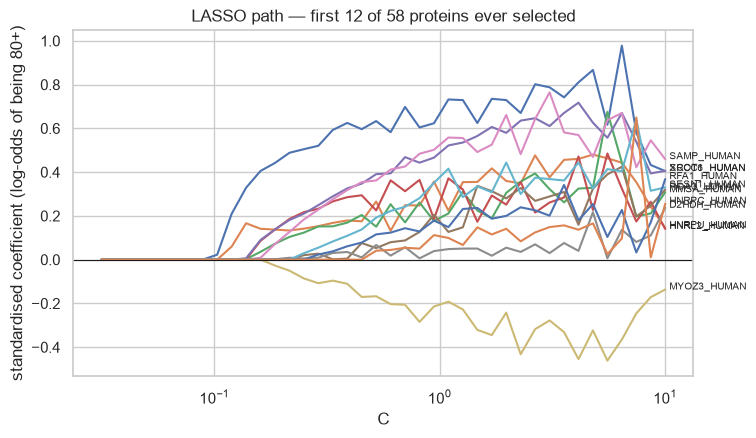

In [6]:
path_Cs = np.logspace(-1.5, 1, 40)
coefs = pd.DataFrame([make_model(C, 1).fit(X, y)[-1].coef_[0] for C in path_Cs], index=path_Cs, columns=X.columns)
entered = coefs.loc[:, (coefs != 0).any()]
first = entered.ne(0).idxmax().sort_values().index[:12]   # the 12 proteins that enter earliest

ax = coefs[first].plot(figsize=(8, 4.5), logx=True, legend=False)
for p in first:
    ax.annotate(p, (path_Cs[-1], coefs[p].iloc[-1]), fontsize=7, xytext=(3, 0), textcoords="offset points")
ax.axhline(0, color="k", lw=0.8)
ax.set(xlabel="C", ylabel="standardised coefficient (log-odds of being 80+)",
       title=f"LASSO path — first 12 of {entered.shape[1]} proteins ever selected");

## 4. Tuning the penalty: nested cross-validation

We need to **choose C** — but if we pick the best C by looking at CV scores and then report that same score, we've used the test folds to make a modelling decision. That score is optimistically biased.

**Nested CV** separates the two jobs:

```
outer loop (performance estimate):    [TEST] [train train train train]
                                              │
inner loop (choose C, train only):           [val][tr][tr][tr]  → best C
```

`GridSearchCV` is the inner loop; wrapping it in `cross_val_score` gives the outer loop.

In [7]:
inner = StratifiedKFold(5, shuffle=True, random_state=SEED)
outer = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED + 1)
grid = GridSearchCV(make_model(l1_ratio=1), {"logisticregression__C": np.logspace(-1, 1.5, 12)},
                    cv=inner, scoring="roc_auc")

grid.fit(X, y)
nested = cross_val_score(grid, X, y, cv=outer, scoring="roc_auc")
print(f"Best C on all data: {grid.best_params_['logisticregression__C']:.3f}")
print(f"Non-nested (best inner CV score, optimistic): AUC = {grid.best_score_:.3f}")
print(f"Nested CV (honest):                           AUC = {nested.mean():.3f} ± {nested.std():.3f}")

Best C on all data: 0.169
Non-nested (best inner CV score, optimistic): AUC = 1.000
Nested CV (honest):                           AUC = 0.980 ± 0.098


Here the gap is small because the signal is strong. With weak signals (most real biomarker problems) and big grids of hyperparameters, the non-nested number can be badly inflated. **Report the nested number.**

## 5. 🚨 Selection leakage: a perfect biomarker made of noise

A very common workflow in omics papers:

1. Run t-tests on all proteins, keep the top 20.
2. Train a classifier on those 20 with cross-validation.
3. Report the CV AUC.

Step 1 used **all samples, including the future test folds**, to choose features. To see how much damage that does, replace the proteomics data with **pure random noise** of the same shape: no real signal can exist.

In [8]:
rng = np.random.default_rng(SEED)
X_noise = pd.DataFrame(rng.normal(size=X.shape), columns=X.columns)
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED)

# Leaky: select the 20 "best" noise features using ALL samples, then cross-validate
X_top = SelectKBest(f_classif, k=20).fit_transform(X_noise, y)
leaky = cross_val_score(make_model(), X_top, y, cv=cv, scoring="roc_auc")

# Honest: selection is part of the pipeline, so it is re-done inside every training fold
honest_pipe = make_pipeline(SelectKBest(f_classif, k=20), StandardScaler(),
                            LogisticRegression(solver="liblinear"))
honest = cross_val_score(honest_pipe, X_noise, y, cv=cv, scoring="roc_auc")

print(f"Random noise, selection outside CV: AUC = {leaky.mean():.2f}   <- looks like a great biomarker")
print(f"Random noise, selection inside CV:  AUC = {honest.mean():.2f}   <- the truth: coin flip")

Random noise, selection outside CV: AUC = 1.00   <- looks like a great biomarker
Random noise, selection inside CV:  AUC = 0.58   <- the truth: coin flip


With 2,509 noise features and 23 samples, *some* features will correlate with the labels by chance. Selecting them on all data and then cross-validating just re-discovers that chance correlation.

**Rule: every step that looks at the labels — feature selection, filtering by variance or fold-change, tuning, even choosing the normalisation — must happen inside the CV loop.** scikit-learn `Pipeline`s make this automatic. The same goes for unsupervised steps fitted on data (scaling, PCA, imputation): fit them on training folds only.

## 6. How stable is the LASSO signature?

Prediction is easy here; but would we find the **same proteins** in a new cohort? A cheap proxy: refit LASSO on many resampled training sets and count how often each protein is selected.

Proteins selected in ≥80% of fits: 1 | ever selected: 27


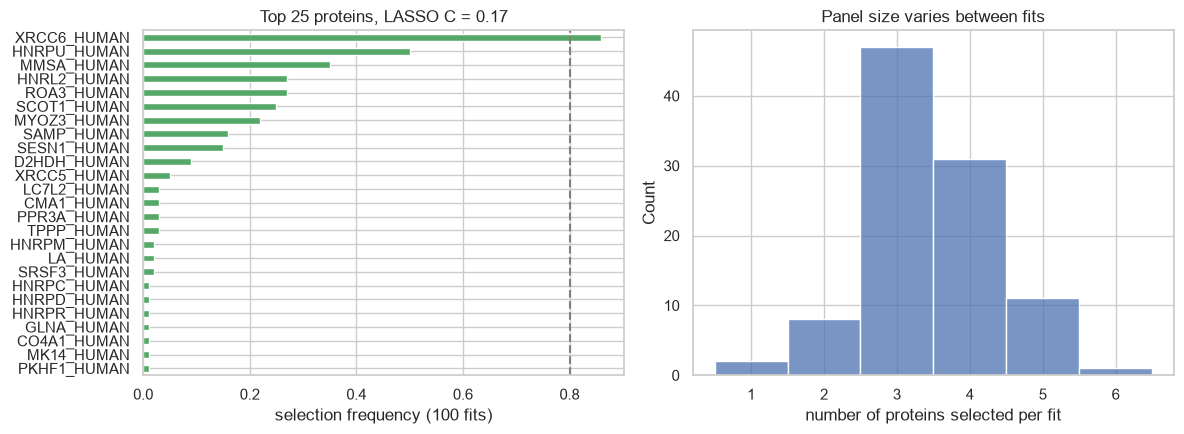

In [9]:
C_best = grid.best_params_["logisticregression__C"]
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=20, random_state=SEED)
selected = []
for train_idx, _ in cv.split(X, y):
    coef = make_model(C_best, 1).fit(X.iloc[train_idx], y.iloc[train_idx])[-1].coef_[0]
    selected.append(coef != 0)
freq = pd.Series(np.mean(selected, axis=0), index=X.columns).sort_values(ascending=False)
sizes = np.sum(selected, axis=1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
freq.head(25).iloc[::-1].plot.barh(ax=axes[0], color="C2")
axes[0].axvline(0.8, ls="--", color="grey")
axes[0].set(xlabel="selection frequency (100 fits)", title=f"Top 25 proteins, LASSO C = {C_best:.2f}")
sns.histplot(sizes, discrete=True, ax=axes[1])
axes[1].set(xlabel="number of proteins selected per fit", title="Panel size varies between fits")
plt.tight_layout()
print(f"Proteins selected in ≥80% of fits: {(freq >= 0.8).sum()} | ever selected: {(freq > 0).sum()}")

The typical picture for omics LASSO, and very visible here:
- a very small **core** of proteins chosen almost every time (credible candidates),
- a long tail of proteins that appear in only some fits (interchangeable, often correlated with the core).

A single LASSO fit on all data reports one confident-looking panel; the resampling shows how much of that panel is luck.

LASSO picks **one representative** from a group of correlated proteins somewhat arbitrarily. If a protein is missing from your panel, it may simply have been "shadowed" by a correlated partner. Stability (and elastic net) help; replication in an independent cohort is the real test.

## 7. Is the whole pipeline better than chance? Permutation test

A permutation test shuffles the labels many times, re-runs the **entire** pipeline (including tuning) and builds a null distribution of scores. The p-value is the fraction of shuffled runs that score at least as well as the real labels.

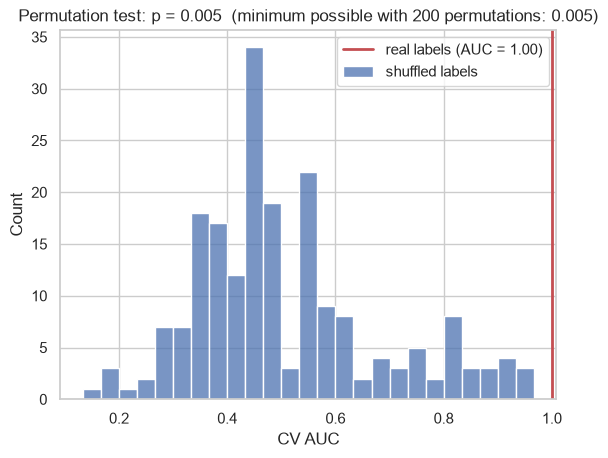

In [10]:
score, perm_scores, p_value = permutation_test_score(
    make_model(C_best, 1), X, y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
    scoring="roc_auc", n_permutations=200, random_state=SEED)

sns.histplot(perm_scores, bins=25, label="shuffled labels")
plt.axvline(score, color="C3", lw=2, label=f"real labels (AUC = {score:.2f})")
plt.title(f"Permutation test: p = {p_value:.3f}  (minimum possible with 200 permutations: {1/201:.3f})")
plt.xlabel("CV AUC"); plt.legend();

## 8. Checklist for p ≫ n biomarker studies

- [ ] Explore first (PCA, coloured by group **and** batch).
- [ ] Use stratified, **repeated** k-fold CV; grouped CV for repeated measures.
- [ ] Put **every** data-driven step (scaling, filtering, selection, tuning) inside a `Pipeline`.
- [ ] Tune hyperparameters with **nested** CV and report the outer score.
- [ ] Prefer regularised models (ridge / LASSO / elastic net) over stepwise selection.
- [ ] Report **selection stability**, not just one signature.
- [ ] Permutation test the whole pipeline; validate in an independent cohort before claiming a biomarker.

## 9. Exercises

**Exercise 1: Prefer the simpler panel.** Instead of the C with the highest CV AUC, practitioners often pick the **smallest C (strongest penalty, fewest proteins)** whose AUC is "close enough" to the best. The classic version is the *one-standard-error rule*; here the best models score AUC = 1.000 in every fold (SE = 0), so use a tolerance of 0.02 AUC instead. Apply it to the LASSO rows of `curve`. How many proteins does that model use?

In [11]:
# your code here

In [12]:
# Solution 1
lasso = curve[curve["model"] == "LASSO"].reset_index(drop=True)
best = lasso.loc[lasso["AUC"].idxmax()]
simple = lasso[lasso["AUC"] >= best["AUC"] - 0.02].sort_values("C").iloc[0]
print(f"best AUC:      C = {best['C']:.3f}, AUC = {best['AUC']:.3f}, proteins = {best['nonzero']}")
print(f"within 0.02:   C = {simple['C']:.3f}, AUC = {simple['AUC']:.3f}, proteins = {simple['nonzero']}")
# A much sparser panel at essentially the same performance: cheaper assay, easier to validate.

best AUC:      C = 21.544, AUC = 1.000, proteins = 53
within 0.02:   C = 0.215, AUC = 0.980, proteins = 8


**Exercise 2: Univariate statistics vs LASSO.** Run a two-sample t-test for every protein (old vs young), correct with Benjamini–Hochberg, and count proteins with FDR < 5%. How many of the LASSO "core" proteins (selected in ≥ 80% of fits) are also FDR-significant? Why might the two lists differ?

In [13]:
# your code here

In [14]:
# Solution 2
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

t, p = ttest_ind(X[y == 1], X[y == 0], axis=0)
fdr = pd.Series(multipletests(p, method="fdr_bh")[1], index=X.columns)
core = freq[freq >= 0.8].index
print(f"FDR < 5%: {(fdr < 0.05).sum()} proteins")
print(f"LASSO core: {len(core)} proteins, of which FDR-significant: {(fdr[core] < 0.05).sum()}")
# Univariate tests ask "does this protein differ on its own?"; LASSO asks "what small set predicts jointly?".
# Many significant proteins are redundant (correlated), so LASSO keeps only a few representatives.

FDR < 5%: 191 proteins
LASSO core: 1 proteins, of which FDR-significant: 1


**Exercise 3: How bad can leakage get?** Repeat the noise experiment from section 5 with `k` = 5, 20, 100 and 500 selected features, for both the leaky and the honest pipeline. Plot AUC against k.

In [15]:
# your code here

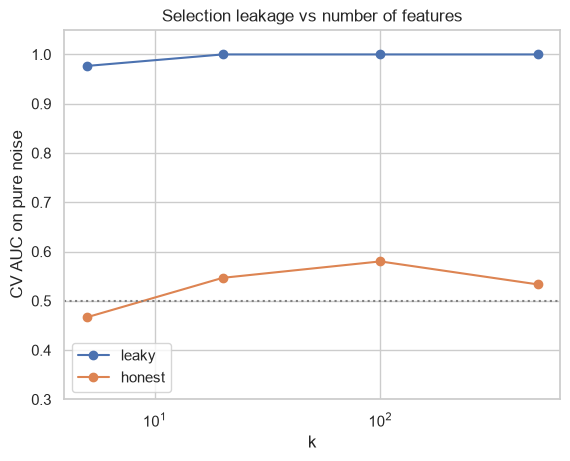

In [16]:
# Solution 3
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)
rows = []
for k in [5, 20, 100, 500]:
    X_top = SelectKBest(f_classif, k=k).fit_transform(X_noise, y)
    rows.append({"k": k, "leaky": cross_val_score(make_model(), X_top, y, cv=cv, scoring="roc_auc").mean(),
                 "honest": cross_val_score(make_pipeline(SelectKBest(f_classif, k=k), StandardScaler(),
                                                         LogisticRegression(solver="liblinear")),
                                           X_noise, y, cv=cv, scoring="roc_auc").mean()})
pd.DataFrame(rows).set_index("k").plot(marker="o", logx=True, ylim=(0.3, 1.05),
                                       ylabel="CV AUC on pure noise", title="Selection leakage vs number of features");
plt.axhline(0.5, color="grey", ls=":");

## Summary

| Concept | Takeaway |
|---|---|
| Single split | With n = 23 it is a lottery; use repeated stratified k-fold |
| Cross-validation | Every sample is tested once per repeat; average over repeats |
| Ridge | Shrinks all coefficients; stable predictions; no selection |
| LASSO | Zeros most coefficients → short panels; picks among correlated proteins arbitrarily |
| C = 1/λ | Small C = strong penalty = fewer proteins |
| Nested CV | Tune in the inner loop, report the outer loop |
| Selection leakage | Selecting features on all data turns pure noise into AUC ≈ 1 |
| Stability | Trust proteins selected consistently across resamples, then replicate |

**Next — Day 4: Random Forests, Gradient Boosting + XGBoost.** Non-linear models that handle interactions and mixed clinical data, how to tune them, and how to interpret them with permutation importance and SHAP.